# heatwave3 in R and Python

`heatwave3` detects marine heatwaves (MHWs) and marine cold-spells (MCSs) directly in gridded NetCDF data, following Hobday et al. (2016, 2018). The R and Python packages share one C++ core, and the Python functions use the same names, arguments and outputs as the R ones.

This notebook:

1. runs the same analysis in both languages, side by side;
2. visualises the results;
3. compares the R and Python outputs, as per-pixel difference maps and as an RMSE table for one pixel.

**Requirements.** A Python environment with `heatwave3`, `matplotlib` and `rpy2`, and R with the `heatwave3` package. R cells (marked `%%R`) run through `rpy2`. While the Python package is in development on the `python-port` branch, the R code is loaded from this repository with `pkgload::load_all()`.

**Data.** By default the notebook uses daily OSTIA SST for 1982 to 2023 on a 31 × 21 grid around Bali and Lombok. Set the environment variable `HW3_NOTEBOOK_SST` to use another file. If neither is available, the small test file bundled with the package is used instead.

## Setup

In [1]:
import os
import tempfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import heatwave3 as hw3

# Repository root (the notebook lives in python/notebooks/)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DESCRIPTION").exists())

SST = Path(os.environ.get("HW3_NOTEBOOK_SST",
                          Path.home() / "pCloudDrive/heatwave3/ostia_sst_1982-2023.nc"))
if not SST.exists():
    SST = REPO / "inst/extdata/sst_test.nc"
CLIM_PERIOD = ("1982-01-01", "2011-12-31")

OUT = Path(tempfile.mkdtemp(prefix="hw3_nb_"))
R_STEM, PY_STEM = str(OUT / "r"), str(OUT / "py")
SST_STR = str(SST)  # passed to R as a plain string
print("heatwave3 (Python)", hw3.__version__, "| data:", SST.name)

heatwave3 (Python) 0.1.0a1 | data: ostia_sst_1982-2023.nc


In [2]:
%load_ext rpy2.ipython

import rpy2.robjects as ro
from rpy2.robjects import default_converter, pandas2ri
from rpy2.robjects.conversion import localconverter

INT_MIN = np.iinfo(np.int32).min


def r_df(name):
    """An R data.frame as pandas, mapping R's Date and NA conventions to pandas."""
    with localconverter(default_converter + pandas2ri.converter):
        df = ro.conversion.get_conversion().rpy2py(ro.globalenv[name])
    is_date = ro.r(f'vapply({name}, function(x) inherits(x, "Date"), logical(1))')
    for col, date in zip(df.columns, is_date):
        x = df[col]
        if date:
            df[col] = pd.to_datetime(x, unit="D")
        elif x.dtype == np.int32:
            df[col] = x.astype("Int32").mask(x == INT_MIN)
        elif x.dtype == object:
            df[col] = [None if v is ro.NA_Character else v for v in x]
    return df.reset_index(drop=True)

In [3]:
%%R
suppressMessages(pkgload::load_all(Sys.getenv("HW3_REPO", "../.."), quiet = TRUE))
cat("heatwave3 (R)", as.character(packageVersion("heatwave3")), "\n")

heatwave3 (R) 1.3.1 


## 1. The same analysis in both languages

Each step is shown as an R cell followed by the equivalent Python cell. Arguments use the R names in both languages: camelCase arguments and snake_case outputs, as in the original Python `marineHeatWaves` code. R vectors such as `c("1982-01-01", "2011-12-31")` become tuples or lists in Python, and `NULL` becomes `None`.

### Climatology and events

`detect3()` runs the climatology (`ts2clm3()`) and event detection (`detect_event3()`) in one call. The outputs are NetCDF files named from the `name` stem. `category = TRUE` adds the Hobday et al. (2018) categories, and `daily = "also"` also writes the per-day series.

In [4]:
%%R -i SST_STR,R_STEM
r_out <- detect3(SST_STR, name = R_STEM, climatologyPeriod = c("1982-01-01", "2011-12-31"),
                 category = TRUE, daily = "also", n_threads = 4, quiet = TRUE)
r_out

                                    clim 
        "/tmp/hw3_nb_uaxdnfps/r_clim.nc" 
                                  events 
      "/tmp/hw3_nb_uaxdnfps/r_events.nc" 
                                   daily 
"/tmp/hw3_nb_uaxdnfps/r_events_daily.nc" 


In [5]:
py_out = hw3.detect3(SST, PY_STEM, CLIM_PERIOD, category=True, daily="also",
                     n_threads=4, quiet=True)
py_out

{'clim': '/tmp/hw3_nb_uaxdnfps/py_clim.nc',
 'events': '/tmp/hw3_nb_uaxdnfps/py_events.nc',
 'daily': '/tmp/hw3_nb_uaxdnfps/py_events_daily.nc'}

### Reading the outputs

`hw3_export()` reads any product into a long table. Passing `vars`, `lon_range`, `lat_range`, `time_range`, `depth_range` or `n` reads only that subset from disk. Passing `file_out` writes a `.csv` or `.parquet` file instead (R also supports `.rds`).

In [6]:
%%R
head(hw3_export(r_out[["events"]], n = 3))

      lon    lat pixel_index event_no date_start  date_peak   date_end duration
1 114.975 -9.025           0        1 1983-03-24 1983-03-25 1983-03-28        5
2 114.975 -9.025           0        2 1983-04-01 1983-04-20 1983-04-30       30
3 114.975 -9.025           0        3 1983-05-04 1983-05-08 1983-05-15       12
  intensity_mean intensity_max intensity_var intensity_cumulative
1         1.3731        1.6252        0.1986               6.8656
2         1.4013        1.9901        0.2638              42.0402
3         2.1372        2.7954        0.5064              25.6460
  intensity_mean_relThresh intensity_max_relThresh intensity_var_relThresh
1                   0.3286                  0.5740                  0.1930
2                   0.3450                  0.9087                  0.2553
3                   1.0286                  1.6955                  0.5165
  intensity_cumulative_relThresh intensity_mean_abs intensity_max_abs
1                         1.6430            30

In [7]:
hw3.hw3_export(py_out["events"], n=3)

,lon,lat,pixel_index,event_no,date_start,date_peak,date_end,duration,intensity_mean,intensity_max,...,intensity_var_abs,intensity_cumulative_abs,rate_onset,rate_decline,category,p_moderate,p_strong,p_severe,p_extreme,season
0,114.974998,-9.025,0,1,1983-03-24,1983-03-25,1983-03-28,5,1.3731,1.6252,...,0.2058,1518.2000,0.2175,0.1418,I Moderate,1.0,0.5460,0.0000,0.0,Fall
1,114.974998,-9.025,0,2,1983-04-01,1983-04-20,1983-04-30,30,1.4013,1.9901,...,0.3184,9099.0298,0.0476,0.0742,I Moderate,1.0,0.8403,0.0000,0.0,Fall
2,114.974998,-9.025,0,3,1983-05-04,1983-05-08,1983-05-15,12,2.1372,2.7954,...,0.5456,3639.5999,0.2967,0.2012,II Strong,1.0,1.0000,0.5415,0.0,Fall


### Categories, annual summaries and a daily window

`category3()` returns the category of each event, `block_average3()` summarises events per pixel and year, and `category_daily3()` returns the full daily grid, with categories, for a date window.

In [8]:
%%R
r_cat <- category3(r_out[["events"]])
r_blk <- block_average3(r_out[["events"]])
r_catd <- category_daily3(SST_STR, r_out[["clim"]], r_out[["events"]],
                          time_range = c("2023-01-01", "2023-12-31"))
head(r_cat, 3)

  event_no     lon    lat  peak_date   category intensity_max duration
1        1 114.975 -9.025 1983-03-25 I Moderate        1.6252        5
2        2 114.975 -9.025 1983-04-20 I Moderate        1.9901       30
3        3 114.975 -9.025 1983-05-08  II Strong        2.7954       12
  p_moderate p_strong p_severe p_extreme season
1          1   0.5460   0.0000         0   Fall
2          1   0.8403   0.0000         0   Fall
3          1   1.0000   0.5415         0   Fall


In [9]:
py_cat = hw3.category3(py_out["events"])
py_blk = hw3.block_average3(py_out["events"])
py_catd = hw3.category_daily3(SST, py_out["clim"], py_out["events"],
                              time_range=("2023-01-01", "2023-12-31"))
py_cat.head(3)

,event_no,lon,lat,peak_date,category,intensity_max,duration,p_moderate,p_strong,p_severe,p_extreme,season
0,1,114.975,-9.025,1983-03-25,I Moderate,1.6252,5,1.0,0.5460,0.0000,0.0,Fall
1,2,114.975,-9.025,1983-04-20,I Moderate,1.9901,30,1.0,0.8403,0.0000,0.0,Fall
2,3,114.975,-9.025,1983-05-08,II Strong,2.7954,12,1.0,1.0000,0.5415,0.0,Fall


### Plotting functions

`event_line3()` plots the temperature, climatology and threshold at one pixel, with the events filled ("flames"), centred on the pixel's strongest event when `event_file` is given. `plot_metric3()` maps an event metric aggregated per pixel. In R they return ggplot2 objects; in Python they draw with matplotlib and return the `Axes`. The building blocks `geom_flame3()` and `geom_lolli3()` are ggplot2 layers in R and functions that draw onto an `Axes` in Python.

In addition: Warning messages:
1: Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead. 
2: Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead. 


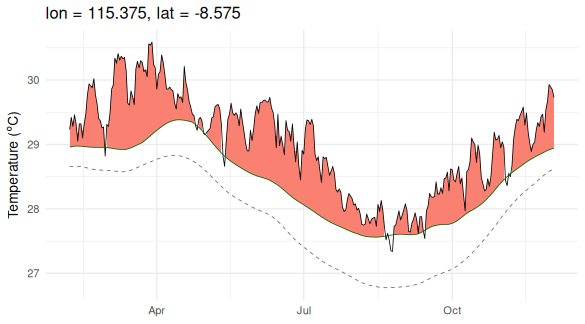

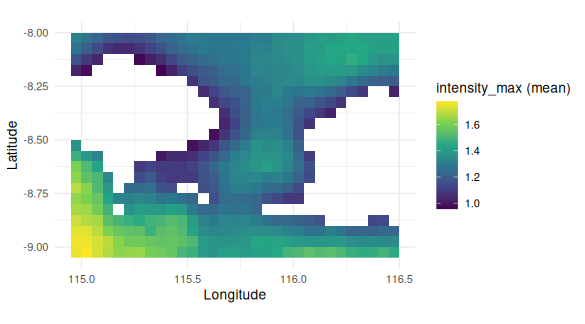

In [10]:
%%R -w 6.5 -h 3.6 --units in -r 90
p_line <- event_line3(SST_STR, r_out[["clim"]], lon = 115.375, lat = -8.575,
                      event_file = r_out[["events"]])
p_map <- plot_metric3(r_out[["events"]], metric = "intensity_max", summary = "mean",
                      coastline = FALSE)
print(p_line)
print(p_map)

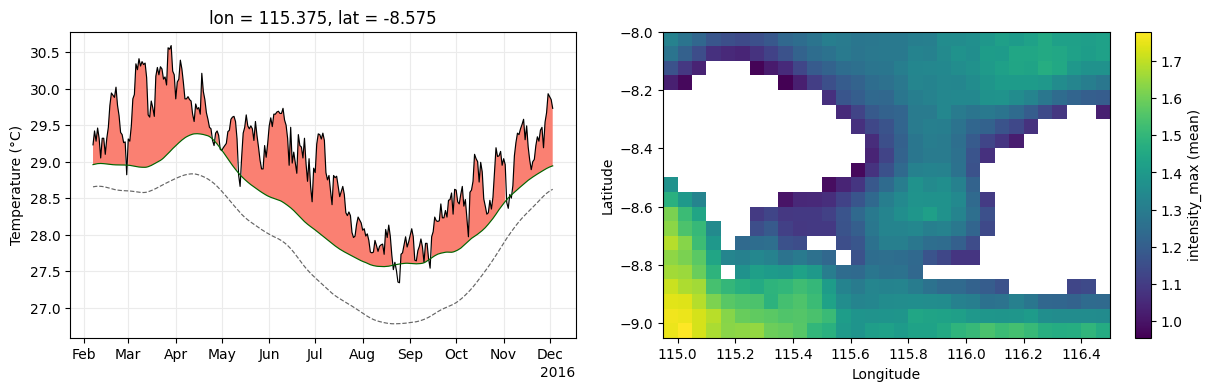

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
hw3.event_line3(SST, py_out["clim"], lon=115.375, lat=-8.575,
                event_file=py_out["events"], ax=axes[0])
hw3.plot_metric3(py_out["events"], metric="intensity_max", summary="mean",
                 coastline=False, ax=axes[1])
plt.show()

## 2. Visualising the output

The figures below use the Python results. They are the same as the R results, as section 3 shows.

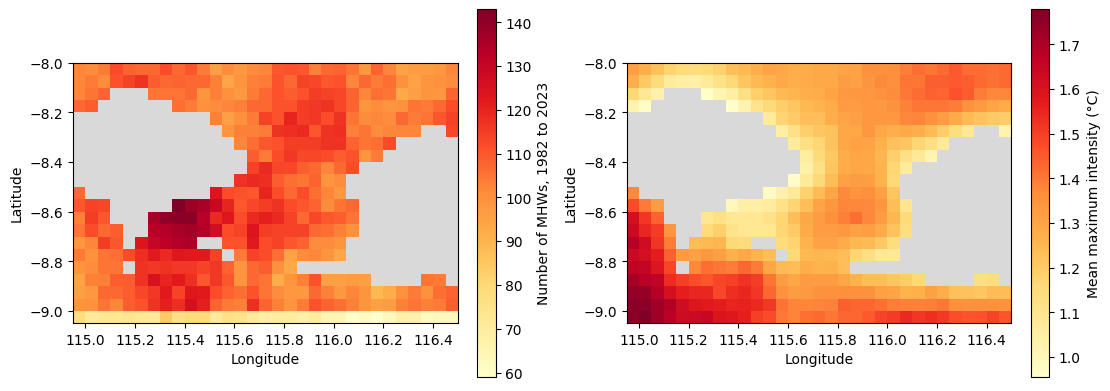

In [12]:
ev = hw3.hw3_export(py_out["events"])
clim = hw3.hw3_export(py_out["clim"])
lons, lats = np.sort(clim["lon"].unique()), np.sort(clim["lat"].unique())


def to_grid(df, value):
    """Pixel table (lon, lat, value) to a [lat, lon] array; missing pixels are NaN."""
    g = df.pivot_table(index="lat", columns="lon", values=value, aggfunc="first")
    return g.reindex(index=lats, columns=lons).to_numpy()


ocean = clim.groupby(["lon", "lat"])["seas"].apply(lambda s: s.notna().any()).reset_index()
per_px = ev.groupby(["lon", "lat"]).agg(n_events=("event_no", "size"),
                                        imax=("intensity_max", "mean")).reset_index()
per_px = ocean.merge(per_px, how="left").fillna({"n_events": 0})
per_px.loc[~per_px["seas"], ["n_events", "imax"]] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, col, label in zip(axes, ["n_events", "imax"],
                          ["Number of MHWs, 1982 to 2023", "Mean maximum intensity (°C)"]):
    ax.set_facecolor("0.85")  # land
    m = ax.pcolormesh(lons, lats, to_grid(per_px, col), cmap="YlOrRd", shading="nearest")
    fig.colorbar(m, ax=ax, label=label)
    ax.set(xlabel="Longitude", ylabel="Latitude", aspect="equal")
plt.show()

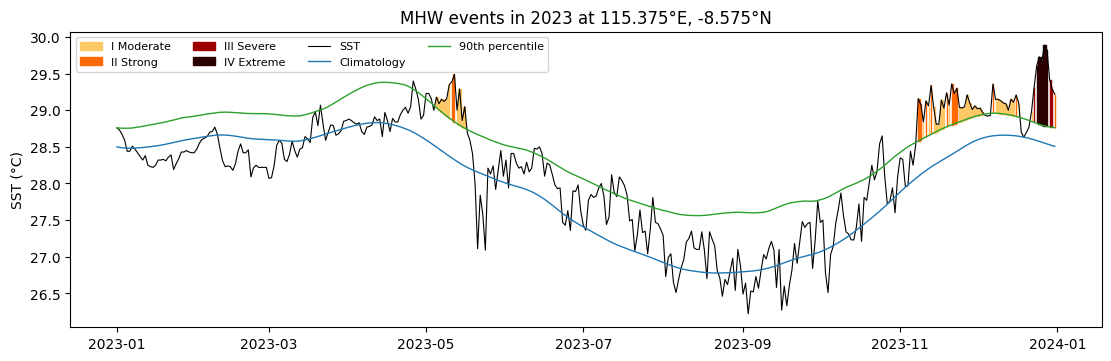

In [13]:
# The pixel with the most events, used for the time series and the RMSE table
PX = per_px.sort_values("n_events", ascending=False).iloc[0]
PX_LON, PX_LAT = float(PX["lon"]), float(PX["lat"])
win = dict(lon_range=(PX_LON, PX_LON), lat_range=(PX_LAT, PX_LAT))

d = hw3.hw3_export(py_out["daily"], time_range=("2023-01-01", "2023-12-31"), **win)
d[["temp", "seas", "thresh"]] -= 273.15  # OSTIA is in kelvin

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
cat_colours = {1: "#ffc866", 2: "#ff6900", 3: "#9e0000", 4: "#2d0000"}
for c, colour in cat_colours.items():
    sel = ((d["category"] == c).fillna(False) & d["event"]).to_numpy(dtype=bool)
    ax.fill_between(d["t"], d["thresh"], d["temp"], where=sel, color=colour, step="mid",
                    label=["I Moderate", "II Strong", "III Severe", "IV Extreme"][c - 1])
ax.plot(d["t"], d["temp"], color="k", lw=0.8, label="SST")
ax.plot(d["t"], d["seas"], color="tab:blue", lw=1, label="Climatology")
ax.plot(d["t"], d["thresh"], color="tab:green", lw=1, label="90th percentile")
ax.set(ylabel="SST (°C)", title=f"MHW events in 2023 at {PX_LON:.3f}°E, {PX_LAT:.3f}°N")
ax.legend(ncol=4, fontsize=8, loc="upper left")
plt.show()

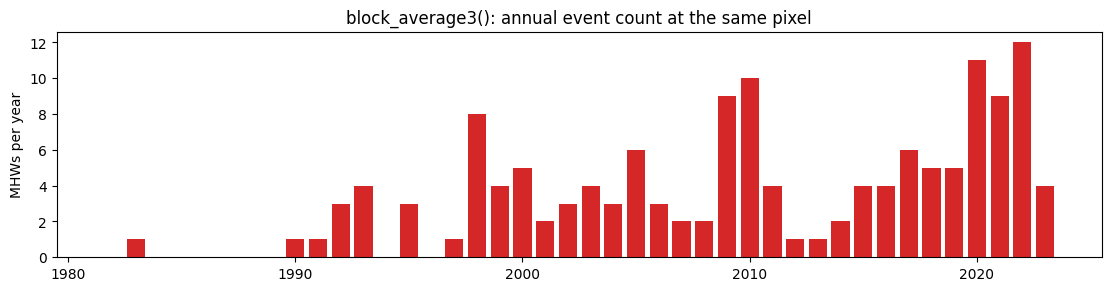

In [14]:
blk = py_blk[(py_blk["lon"] == PX_LON) & (py_blk["lat"] == PX_LAT)]
years = pd.DataFrame({"year": np.arange(1982, 2024)}).merge(blk, how="left").fillna({"count": 0})
fig, ax = plt.subplots(figsize=(11, 2.8), constrained_layout=True)
ax.bar(years["year"], years["count"], color="tab:red")
ax.set(ylabel="MHWs per year", title="block_average3(): annual event count at the same pixel")
plt.show()

## 3. Comparing the R and Python outputs

The two languages run the same C++ core, so the outputs should be identical, not merely close. Each comparison matches rows on their keys (pixel and day-of-year, date or event number) rather than on row order. With `n_threads > 1`, the order of rows in the events table depends on thread scheduling, but the events themselves do not.

### Difference maps

For each pixel, each map shows the root-mean-square difference between R and Python for one output: over the 366 days of the climatology, over every day of 2023 for the daily series, and as the absolute difference of the per-pixel event count and mean maximum intensity for the events. Land pixels are grey, and a map that is uniformly zero means the outputs are identical at every pixel.

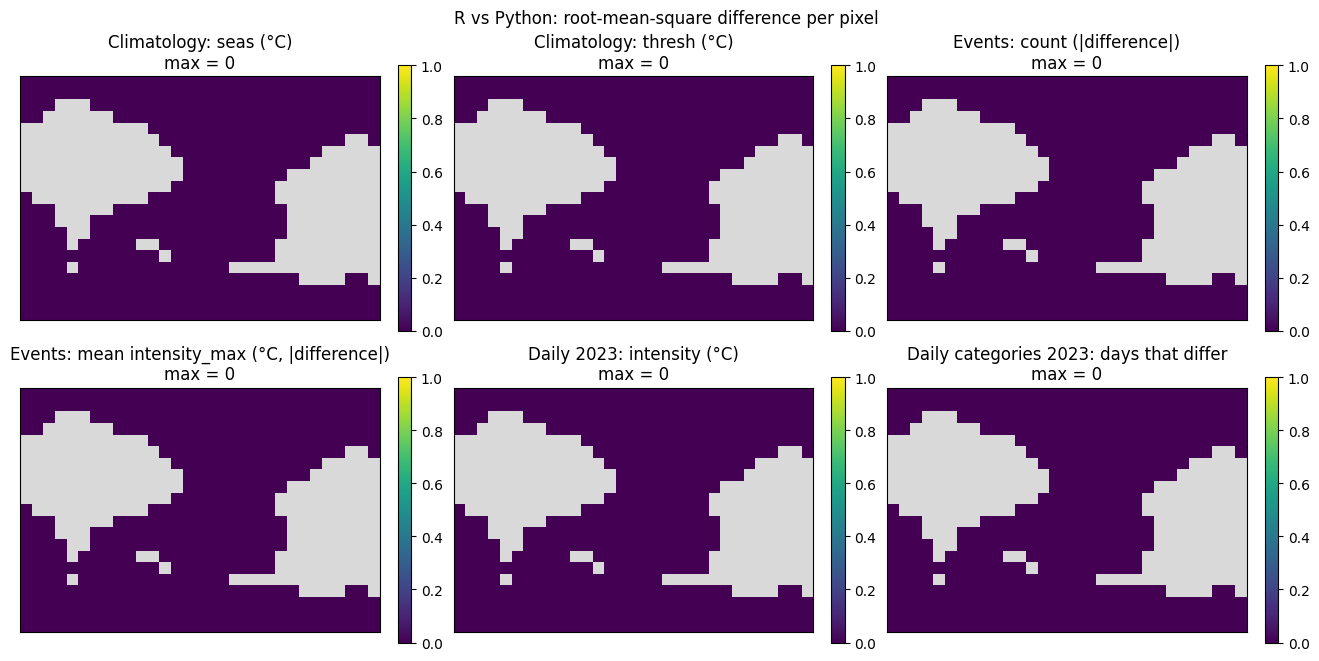

In [15]:
r_cat, r_blk, r_catd = r_df("r_cat"), r_df("r_blk"), r_df("r_catd")
YEAR = ("2023-01-01", "2023-12-31")


def products(out):
    """The NetCDF products of one run, read with the same reader."""
    return {"clim": hw3.hw3_export(out["clim"]),
            "events": hw3.hw3_export(out["events"]),
            "daily": hw3.hw3_export(out["daily"], time_range=YEAR)}


r_paths = dict(zip(ro.r("names(r_out)"), ro.r("unname(r_out)")))
R, P = products(r_paths), products(py_out)
R.update(category_daily=r_catd)
P.update(category_daily=py_catd)
KEYS = {"clim": ["lon", "lat", "doy"], "events": ["lon", "lat", "event_no"],
        "daily": ["lon", "lat", "t"], "category_daily": ["lon", "lat", "t"]}


def paired(product, a=R, b=P):
    """R and Python rows of one product, matched on their keys."""
    m = a[product].merge(b[product], on=KEYS[product], how="outer",
                         suffixes=("_r", "_py"), indicator=True)
    assert (m["_merge"] == "both").all(), f"{product}: unmatched rows"
    return m


def rms_by_pixel(m, var):
    diff = (m[f"{var}_r"].astype(float) - m[f"{var}_py"].astype(float)) ** 2
    both_na = m[f"{var}_r"].isna() & m[f"{var}_py"].isna()
    out = m.assign(sq=diff.mask(both_na, 0.0)).groupby(["lon", "lat"])["sq"].mean()
    return np.sqrt(out).rename("rms").reset_index()


def count_by_pixel(m, var):
    neq = ~((m[f"{var}_r"] == m[f"{var}_py"]).fillna(False)
            | (m[f"{var}_r"].isna() & m[f"{var}_py"].isna())).to_numpy(dtype=bool)
    return m.assign(n=neq).groupby(["lon", "lat"])["n"].sum().rename("rms").reset_index()


def event_summary_diff(a, b, how):
    # |difference| of a per-pixel event summary (count or mean intensity_max)
    s = [x["events"].groupby(["lon", "lat"])["intensity_max"].agg(how).rename("v").reset_index()
         for x in (a, b)]
    m = ocean[["lon", "lat"]].merge(s[0], how="left").merge(
        s[1], on=["lon", "lat"], how="left", suffixes=("_a", "_b"))
    if how == "size":
        m = m.fillna(0)
    return m.assign(rms=(m["v_a"] - m["v_b"]).abs().fillna(0))


def diff_maps(a=R, b=P):
    pc, pd_, pk = (paired(p, a, b) for p in ("clim", "daily", "category_daily"))
    return {
        "Climatology: seas (°C)": rms_by_pixel(pc, "seas"),
        "Climatology: thresh (°C)": rms_by_pixel(pc, "thresh"),
        "Events: count (|difference|)": event_summary_diff(a, b, "size"),
        "Events: mean intensity_max (°C, |difference|)": event_summary_diff(a, b, "mean"),
        "Daily 2023: intensity (°C)": rms_by_pixel(pd_, "intensity"),
        "Daily categories 2023: days that differ": count_by_pixel(pk, "category"),
    }


def plot_maps(maps, title):
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), constrained_layout=True)
    for ax, (label, df) in zip(axes.flat, maps.items()):
        g = to_grid(ocean.merge(df[["lon", "lat", "rms"]], how="left").assign(
            rms=lambda x: x["rms"].astype(float).where(x["seas"].astype(bool))), "rms")
        top = np.nanmax(g)
        ax.set_facecolor("0.85")
        m = ax.pcolormesh(lons, lats, g, cmap="viridis", shading="nearest",
                          vmin=0, vmax=top if top > 0 else 1)
        fig.colorbar(m, ax=ax)
        ax.set(title=f"{label}\nmax = {top:.3g}", aspect="equal", xticks=[], yticks=[])
    fig.suptitle(title)
    plt.show()


plot_maps(diff_maps(), "R vs Python: root-mean-square difference per pixel")

### RMSE at one pixel, for every output

The table compares every numeric output column at the pixel with the most events. It covers the climatology, the events table, the full 42-year daily series, the category and block-average summaries, and the daily-category window. An `RMSE` and a `max |diff|` of zero, with `identical` true, mean the two languages agree exactly, including where values are missing. Text columns (category and season labels) are checked for equality only.

In [16]:
def pixel_rows(df):
    # category3() rounds lon/lat to 4 decimals, so match within a tolerance
    return df[np.isclose(df["lon"], PX_LON, atol=1e-3) & np.isclose(df["lat"], PX_LAT, atol=1e-3)]


full_daily = {k: hw3.hw3_export(o, **win) for k, o in
              (("r", f"{R_STEM}_events_daily.nc"), ("py", py_out["daily"]))}
tables = {  # product: (R table, Python table, key columns)
    "ts2clm3": (R["clim"], P["clim"], KEYS["clim"]),
    "detect_event3": (R["events"], P["events"], KEYS["events"]),
    "daily series": (full_daily["r"], full_daily["py"], KEYS["daily"]),
    "category3": (r_cat, py_cat, ["lon", "lat", "event_no"]),
    "block_average3": (r_blk, py_blk, ["lon", "lat", "year"]),
    "category_daily3": (r_catd, py_catd, KEYS["category_daily"]),
}
rows = []
for product, (a, b, keys) in tables.items():
    m = pixel_rows(a).merge(pixel_rows(b), on=keys, suffixes=("_r", "_py"), how="outer",
                            indicator=True)
    assert (m["_merge"] == "both").all()
    for col in [c for c in a.columns if c not in keys]:
        x, y = m[f"{col}_r"], m[f"{col}_py"]
        if pd.api.types.is_datetime64_any_dtype(x):
            x, y = x.astype("int64"), y.astype("int64")
        if not (pd.api.types.is_numeric_dtype(x) or pd.api.types.is_bool_dtype(x)):
            same = [u == v or (pd.isna(u) and pd.isna(v)) for u, v in zip(x, y)]
            rows.append({"product": product, "column": col, "n": len(x), "RMSE": np.nan,
                         "max |diff|": np.nan, "identical": all(same)})
            continue  # labels (category, season): equality only
        x, y = x.astype(float).to_numpy(), y.astype(float).to_numpy()
        d = np.where(np.isnan(x) & np.isnan(y), 0.0, x - y)
        rows.append({"product": product, "column": col, "n": len(d),
                     "RMSE": np.sqrt(np.nanmean(d ** 2)) if len(d) else 0.0,
                     "max |diff|": np.nanmax(np.abs(d)) if len(d) else 0.0,
                     "identical": bool(np.array_equal(x, y, equal_nan=True))})
rmse = pd.DataFrame(rows)
print(f"Pixel {PX_LON:.3f}°E, {PX_LAT:.3f}°N: {len(rmse)} columns compared over "
      f"{rmse['n'].sum():,} values; all identical: {rmse['identical'].all()}")
rmse.style.format({"RMSE": "{:.3g}", "max |diff|": "{:.3g}"}, na_rep="(labels)").hide(axis="index")

Pixel 115.375°E, -8.575°N: 59 columns compared over 115,826 values; all identical: True


product,column,n,RMSE,max |diff|,identical
ts2clm3,seas,366,0,0,True
ts2clm3,thresh,366,0,0,True
detect_event3,pixel_index,143,0,0,True
detect_event3,date_start,143,0,0,True
detect_event3,date_peak,143,0,0,True
detect_event3,date_end,143,0,0,True
detect_event3,duration,143,0,0,True
detect_event3,intensity_mean,143,0,0,True
detect_event3,intensity_max,143,0,0,True
detect_event3,intensity_var,143,0,0,True


## 4. Spatially connected blobs

`detect_blob3()` links exceedance days that touch in longitude, latitude and time (and depth, for a depth-resolved climatology) into spatially coherent events ("blobs"), and summarises each blob per day and overall. The R argument `return` is called `return_` in Python, because `return` is a Python keyword.

The labelling and the per-day metrics run in the shared C++ core in both languages; the exceedance mask and the per-blob summaries are vectorised in R and in numpy/pandas respectively. On this grid both take a second or two.

In [17]:
%%R
r_blob <- detect_blob3(SST_STR, r_out[["clim"]], return = c("event", "daily", "voxel"))
r_blob_event <- r_blob$event
head(r_blob_event[, c("blob", "duration", "date_start", "date_end", "cumI_km2_day", "peakArea_km2", "rank")], 3)

  blob duration date_start   date_end cumI_km2_day peakArea_km2 rank
1 1983      317 2016-02-05 2016-12-17      3860564     12562.74    1
2  782      182 1998-05-07 1998-11-04      2544991     13511.29    2
3 2578      253 2022-03-23 2022-11-30      2127045     12562.74    3


In [18]:
py_blob = hw3.detect_blob3(SST, py_out["clim"], return_=("event", "daily", "voxel"))
py_blob["event"][["blob", "duration", "date_start", "date_end", "cumI_km2_day",
                  "peakArea_km2", "rank"]].head(3)

,blob,duration,date_start,date_end,cumI_km2_day,peakArea_km2,rank
0,1983,317,2016-02-05,2016-12-17,3.860564e+06,12562.744590,1
1,782,182,1998-05-07,1998-11-04,2.544991e+06,13511.289393,2
2,2578,253,2022-03-23,2022-11-30,2.127045e+06,12562.744590,3


In [19]:
# Blob-level comparison. Columns aggregated with sum()/mean() can differ in the
# last bit or two, because R accumulates sums in 80-bit long double.
r_be, p_be = r_df("r_blob_event"), py_blob["event"]
rows = []
for col in p_be.columns:
    x, y = r_be[col], p_be[col]
    if pd.api.types.is_datetime64_any_dtype(x):
        x, y = x.astype("int64"), y.astype("int64")
    x, y = x.to_numpy(dtype=float), y.to_numpy(dtype=float)
    rows.append({"column": col, "identical values": int((x == y).sum()), "of": len(x),
                 "max relative difference": float(np.max(np.abs(x - y) / np.maximum(np.abs(x), 1e-300)))})
print(f"{len(p_be)} blobs in Python, {len(r_be)} in R; same blobs in the same order: "
      f"{np.array_equal(r_be['blob'], p_be['blob'])}")
pd.DataFrame(rows).style.format({"max relative difference": "{:.1e}"}).hide(axis="index")

2791 blobs in Python, 2791 in R; same blobs in the same order: True


column,identical values,of,max relative difference
blob,2791,2791,0.0e+00
duration,2791,2791,0.0e+00
date_start,2791,2791,0.0e+00
date_end,2791,2791,0.0e+00
date_peak,2791,2791,0.0e+00
cumI_km2_day,2717,2791,2.2e-16
peakArea_km2,2791,2791,0.0e+00
meanArea_km2,2534,2791,2.2e-16
centroid_lon,2667,2791,3.7e-16
centroid_lat,2706,2791,4.4e-16


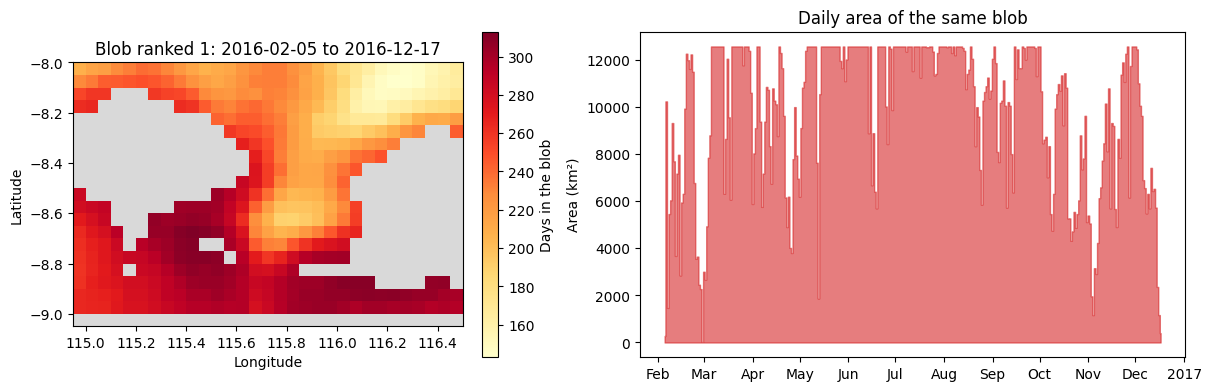

In [20]:
top = py_blob["event"].iloc[0]
vox = py_blob["voxel"][py_blob["voxel"]["blob"] == top["blob"]]
days = vox.groupby(["lon", "lat"]).size().rename("days").reset_index()
daily = py_blob["daily"][py_blob["daily"]["blob"] == top["blob"]].set_index("date")["area_km2"]
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)  # absent days = 0

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.set_facecolor("0.85")
grid = to_grid(ocean.merge(days, how="left").assign(
    days=lambda x: x["days"].where(x["seas"].astype(bool))), "days")
m = ax.pcolormesh(lons, lats, grid, cmap="YlOrRd", shading="nearest")
fig.colorbar(m, ax=ax, label="Days in the blob")
ax.set(xlabel="Longitude", ylabel="Latitude", aspect="equal",
       title=f"Blob ranked 1: {top['date_start']:%Y-%m-%d} to {top['date_end']:%Y-%m-%d}")
ax = axes[1]
ax.fill_between(daily.index, daily.to_numpy(), color="tab:red", alpha=0.6, step="mid")
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set(ylabel="Area (km²)", title="Daily area of the same blob")
plt.show()

### For scale: what a real difference looks like

Uniformly zero maps can look empty. For comparison, here are the same maps for two Python runs whose only difference is the threshold percentile, 90 versus 91.

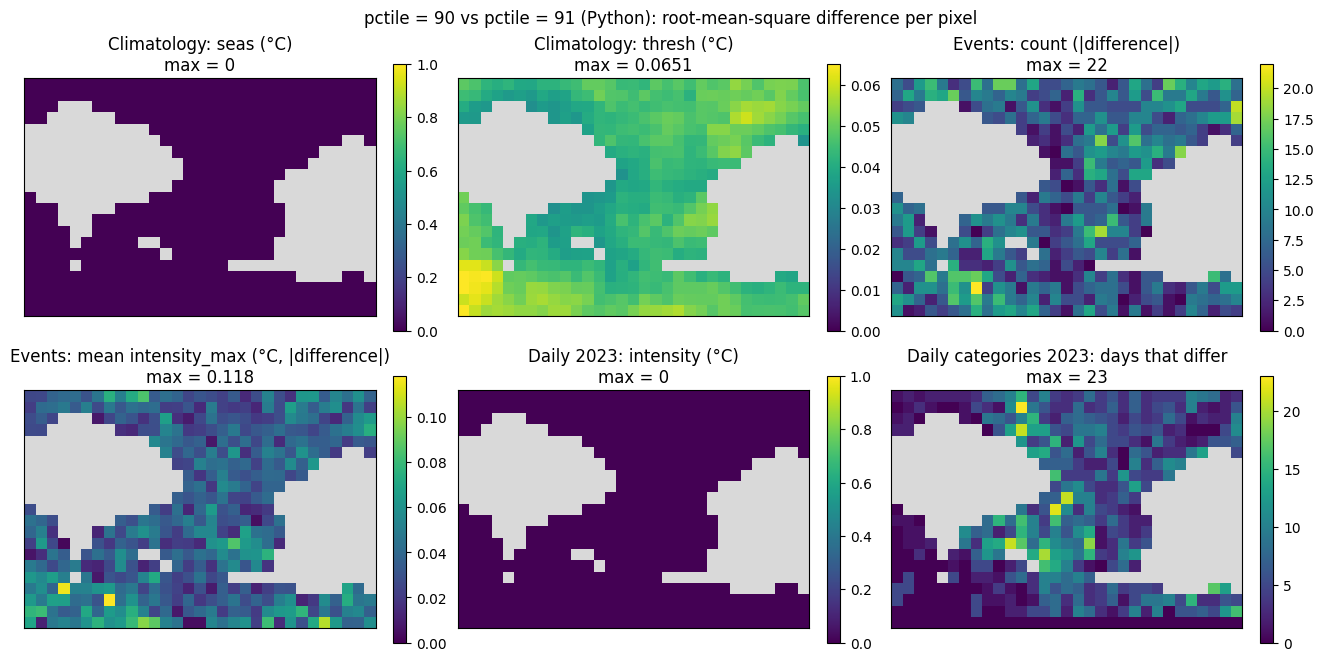

In [21]:
alt = hw3.detect3(SST, str(OUT / "py91"), CLIM_PERIOD, pctile=91, category=True,
                  daily="also", n_threads=4, quiet=True)
A = products(alt)
A["category_daily"] = hw3.category_daily3(SST, alt["clim"], alt["events"], time_range=YEAR)
plot_maps(diff_maps(P, A), "pctile = 90 vs pctile = 91 (Python): root-mean-square difference per pixel")

Raising the percentile from 90 to 91 raises the threshold by up to about 0.07 °C (root-mean-square over the year) and changes the event counts (by up to 22 per pixel), the mean maximum intensities and the 2023 daily categories across most ocean pixels. The seasonal climatology and the daily intensity (SST minus climatology) are unchanged, as expected, because the percentile only moves the threshold. Differences of this size would be obvious in the R versus Python maps above, which show none.